In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q matplotlib pytest numpy
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    os.chdir(repo_root)
    print("💻 ローカル開発環境を検出しました。作業ディレクトリ:", os.getcwd())


💻 ローカル開発環境を検出しました。作業ディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 9.4 重ね合わせ処理の時間計測 (Profiling Compositing Performance) (`osbook_day09b`)

本節では、第9章 9.3節で実装したウィンドウ・レイヤ重ね合わせ描画（`LayerManager::Draw()`）における**描画処理時間の正確なプロファイリング（時間計測）**を行います。

> [!IMPORTANT]
> **パフォーマンスチューニングの絶対鉄則**: **「推測するな、計測せよ」（Measure, Don't Guess）**  
> 直感やあて推量で最適化を行うのではなく、ハードウェアタイマを用いて処理のボトルネックをミリ秒・クロック単位で定量化し、データに基づいて高速化の設計を行うことが OS 開発において極めて重要です。

---

### 前節までの課題と本節の動機 (Motivation)

9.3節（`osbook_day09a`）において、MikanOS は `Window`, `Layer`, `LayerManager` によるレイヤ抽象化を獲得しました。これにより、デスクトップ背景、コンソール、マウスカーソルが正しい重ね合わせ順序（Z-order）で合成表示できるようになりました。

しかし、実際に QEMU や実機上でマウスを動かしてみると、**「マウスポインタの移動が著しくもたつき、カクカクして操作についてこない」** という強烈な遅延が発生します。

#### なぜ遅いのか？
1. **全画面再描画の暴力性**: マウスがわずか 1 ピクセル動いただけでも、`MouseObserver` は `layer_manager->Draw()` を呼び出します。
2. **無駄なピクセル走査**: `Draw()` は、最背面のデスクトップレイヤ（$1024 \times 768 \approx 786,432$ ピクセル）、コンソールレイヤ、マウスレイヤのすべてを、毎回全画面分 VRAM（フレームバッファ）に上書き描画（画家アルゴリズム）します。
3. **VRAM 書き込み帯域幅の限界**: 32bpp（4バイト/ピクセル）の場合、1フレームの再描画だけで約 **3.15 MB** のメモリアクセスが発生します。USB マウスの割り込みが 100 Hz（10ms間隔）で届くのに対し、全画面再描画に 20〜30ms かかってしまうと、イベント処理が破綻し、マウスが激しく遅延します。

このボトルネックを科学的に証明するため、本節では CPU コア内蔵の **Local APIC (LAPIC) タイマ** を使用した精密な時間計測機構をカーネルに組み込みます。


---

## 1. Local APIC (LAPIC) タイマのアーキテクチャとハードウェア仕様

x86-64 プロセッサには、各 CPU コアごとに専用の割り込み・時間管理機構である **Local APIC (Advanced Programmable Interrupt Controller)** が内蔵されています。

### 1.1 Local APIC の物理メモリ空間配置 (MMIO)

Local APIC のレジスタ群は、I/O ポート（`in`/`out` 命令）ではなく、物理メモリアドレス空間にマップされた **MMIO (Memory Mapped I/O)** としてアクセスします。
- デフォルトの物理ベースアドレス: `0xFEE00000` (4KiB ページ)
- MikanOS では、第8章で設定した恒等マッピング（Identity Mapping）により、カーネルから直接 `0xFEE0xxxx` 番地の物理ポインタを参照できます。

```mermaid
flowchart TD
    CPU["CPU Core (x86-64)"]
    subgraph Local_APIC ["Local APIC (Base: 0xFEE00000)"]
        DCR["Divide Configuration Register (DCR)\nOffset: 0x3E0 (分周比設定)"]
        LVT["LVT Timer Register\nOffset: 0x320 (モード・マスク・ベクタ)"]
        ICR["Initial Count Register (ICR)\nOffset: 0x380 (カウント初期値書き込み)"]
        CCR["Current Count Register (CCR)\nOffset: 0x390 (現在値デクリメント, Read-Only)"]
    end
    CPU -->|"MMIO Read / Write"| Local_APIC
    DCR -.->|"分周クロック供給"| CCR
    ICR -->|"カウントロード"| CCR
```

### 1.2 主要レジスタのビット構成と数理仕様

#### (1) Divide Configuration Register (DCR: `0xFEE003E0`)
タイマ基準クロック（Core crystal clock または Bus clock）の**分周比（Divider）**を決定します。
- ビット 3, 1, 0 の 3 ビットで分周比を指定します（ビット 2 は常に 0）：

| ビット `[3:0]` | 2進表現 | 分周比 (Divider) | 説明 |
|:---:|:---:|:---:|:---|
| `0x0` | `0b0000` | 1 / 2 | クロックを 2 分周 |
| `0x1` | `0b0001` | 1 / 4 | クロックを 4 分周 |
| `0x2` | `0b0010` | 1 / 8 | クロックを 8 分周 |
| `0x3` | `0b0011` | 1 / 16 | クロックを 16 分周 |
| `0x8` | `0b1000` | 1 / 32 | クロックを 32 分周 |
| `0x9` | `0b1001` | 1 / 64 | クロックを 64 分周 |
| `0xA` | `0b1010` | 1 / 128 | クロックを 128 分周 |
| **`0xB`** | **`0b1011`** | **1 / 1** | **分周なし (1:1, 最大分解能)** |

> MikanOS では、最も分解能の高い **`divide_config = 0b1011;` (1:1)** を採用しています。

#### (2) LVT Timer Register (`0xFEE00320`)
Local Vector Table のタイマエントリです。
- **ビット `7:0` (Vector)**: タイマ割り込み発生時に CPU に通知する割り込みベクタ番号（MikanOS では 32）。
- **ビット `16` (Mask)**: `1` にすると割り込みをマスク（抑止）。`0` で割り込み許可。
- **ビット `18:17` (Timer Mode)**:
  - `00b`: **One-shot モード**（初期カウントから 0 までデクリメントして停止）。
  - `01b`: **Periodic モード**（0 になると初期値を再ロードして周期的に割り込み発生）。
  - `10b`: **TSC-Deadline モード**（IA32_TSC_DEADLINE MSR による時刻一致起動）。

> 本節の時間計測では、割り込みハンドラを動かすのではなく**純粋なストップウォッチ（経過クロック計測器）**として使いたいため、
> `lvt_timer = (0b001 << 16) | 32;`  
> （ビット16=1 でマスク、ビット18:17=00 でワンショット、ベクタ=32）を設定します。

#### (3) Initial Count Register (`0xFEE00380`) & Current Count Register (`0xFEE00390`)
- `initial_count` に 32 ビット値（例えば `0xFFFFFFFF`）を書き込むと、即座にタイマがカウントダウンを開始します。
- `current_count` から現在値（Read-Only）を読み取ることで、減算された経過カウントが求まります：

$$\text{Elapsed Counts} = \text{Initial Count} - \text{Current Count} = 0\text{xFFFFFFFF} - \text{current\_count}$$

- `initial_count = 0;` を書き込むとタイマは直ちに停止します。


In [2]:
# Python による Local APIC タイマ MMIO レジスタ動作シミュレーション
from common import LAPICTimerRegisterSim

lapic = LAPICTimerRegisterSim()
print("=== Local APIC タイマ初期状態 ===")
print(f"Base Address       : 0x{lapic.APIC_BASE:08X}")
print(f"Divide Config      : 0b{lapic.divide_config:04b} (Divider = {lapic.divider}:1)")
print(f"LVT Timer Register : 0x{lapic.lvt_timer:08X}")
print(f"  - Masked         : {lapic.is_masked}")
print(f"  - Timer Mode     : {lapic.timer_mode}")
print(f"  - Vector         : {lapic.vector}")

# タイマ計測の模擬実行
print("\n=== ストップウォッチ計測シミュレーション ===")
lapic.start()  # initial_count = 0xFFFFFFFF
print(f"Start() 直後の Current Count: 0x{lapic.current_count:08X}, Elapsed: {lapic.elapsed()}")

# 100,000 クロックサイクルの処理が経過したと仮定
lapic.tick_cycles(100_000)
print(f"100,000 cycles 経過後: Current Count: 0x{lapic.current_count:08X}, Elapsed: {lapic.elapsed()} ticks")

lapic.stop()
print(f"Stop() 後のタイマ状態: is_running={lapic.is_running}")


=== Local APIC タイマ初期状態 ===
Base Address       : 0xFEE00000
Divide Config      : 0b1011 (Divider = 1:1)
LVT Timer Register : 0x00010020
  - Masked         : True
  - Timer Mode     : One-shot
  - Vector         : 32

=== ストップウォッチ計測シミュレーション ===
Start() 直後の Current Count: 0xFFFFFFFF, Elapsed: 0
100,000 cycles 経過後: Current Count: 0xFFFE795F, Elapsed: 100000 ticks
Stop() 後のタイマ状態: is_running=False


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:34666: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:34666: UserWarning: Glyph 21608 (\N{CJK UNIFIED IDEOGRAPH-5468}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:34666: UserWarning: Glyph 12510 (\N{KATAKANA LETTER MA}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:34666: UserWarning: Glyph 12473 (\N{KATAKANA LETTER SU}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:34666: UserWarning: Glyph 12463 (\N{KATAKANA LETTER KU}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout(rect=[0, 0,

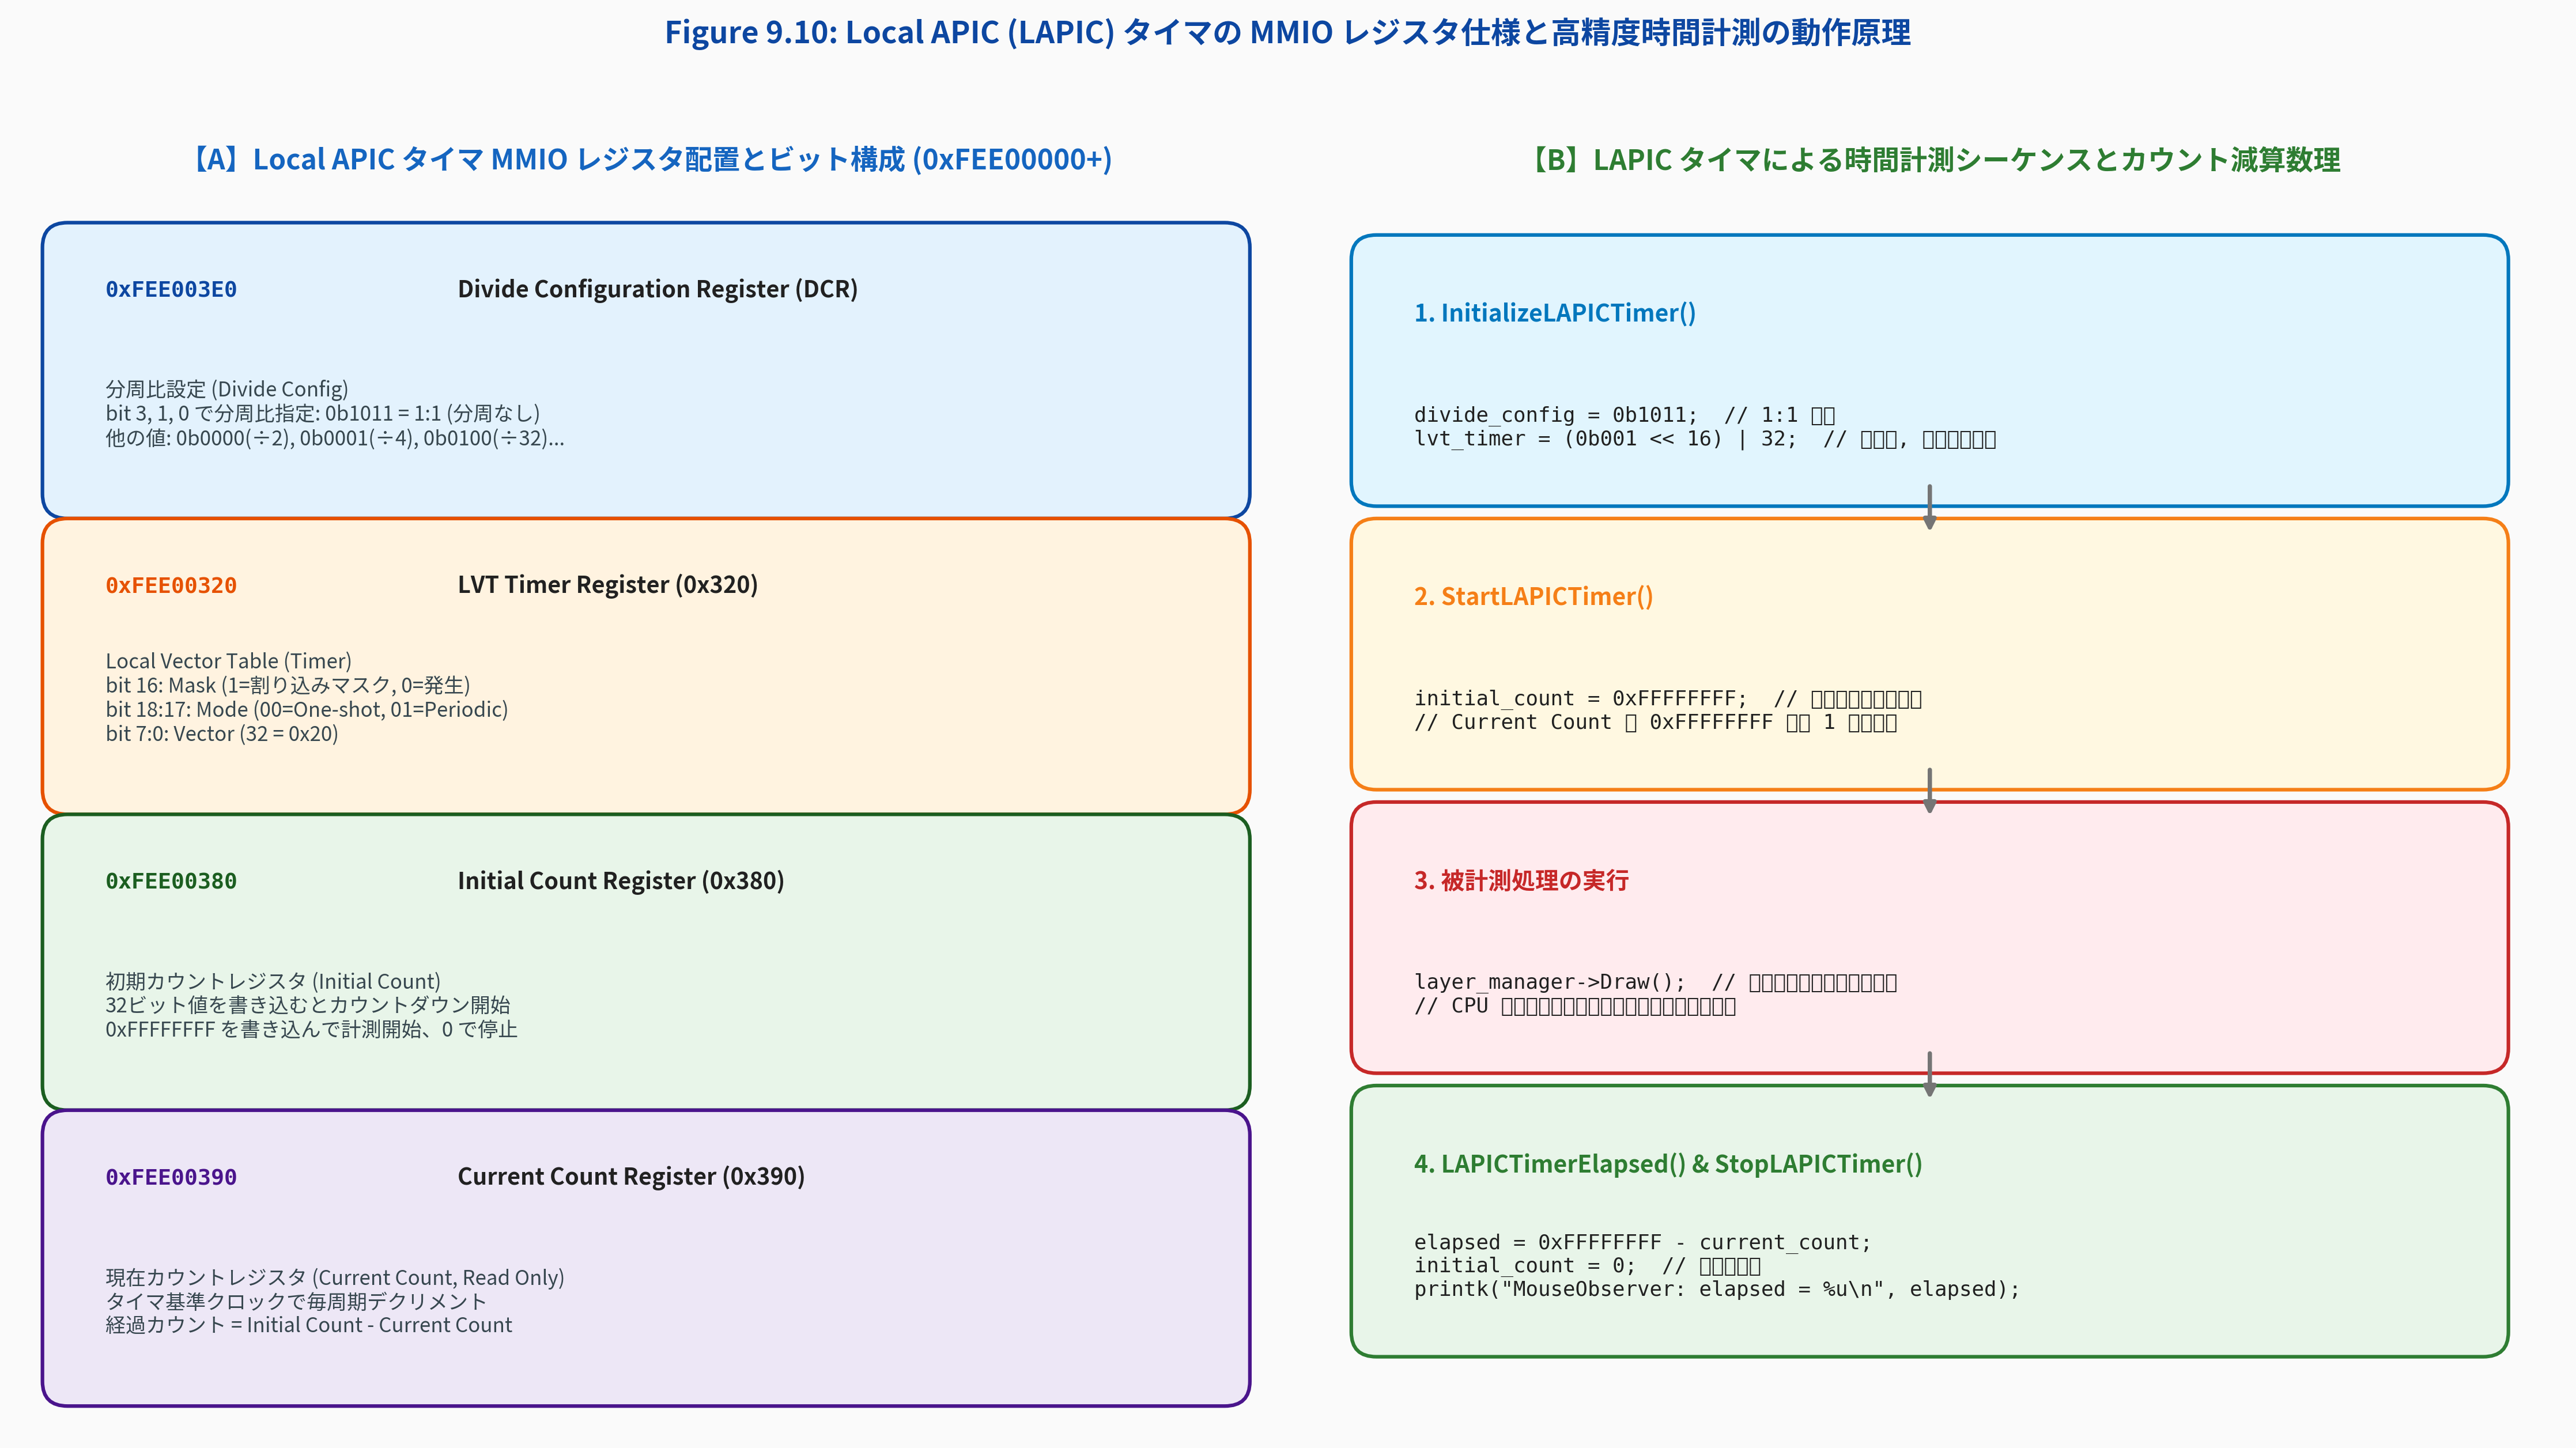

In [3]:
# Figure 9.10: Local APIC タイマの MMIO レジスタ構造と計測シーケンス図版生成
from common import plot_fig9_10_lapic_timer_architecture_and_mmio_registers
from IPython.display import Image, display

fig_path = plot_fig9_10_lapic_timer_architecture_and_mmio_registers()
display(Image(filename=str(fig_path)))


---

## 2. MikanOS におけるタイマ実装 (`osbook_day09b` のコード差分)

MikanOS では、Local APIC タイマを操作するモジュールとして `kernel/timer.hpp` および `kernel/timer.cpp` を新設します。

### 2.1 `kernel/timer.hpp` (タイマ API 宣言)

```cpp
#pragma once
#include <cstdint>

void InitializeLAPICTimer();
void StartLAPICTimer();
uint32_t LAPICTimerElapsed();
void StopLAPICTimer();
```

### 2.2 `kernel/timer.cpp` (MMIO ポインタ定義と実装)

```cpp
#include "timer.hpp"

namespace {
  const uint32_t kCountMax = 0xffffffffu;
  volatile uint32_t& lvt_timer     = *reinterpret_cast<uint32_t*>(0xfee00320);
  volatile uint32_t& initial_count = *reinterpret_cast<uint32_t*>(0xfee00380);
  volatile uint32_t& current_count = *reinterpret_cast<uint32_t*>(0xfee00390);
  volatile uint32_t& divide_config = *reinterpret_cast<uint32_t*>(0xfee003e0);
}

void InitializeLAPICTimer() {
  divide_config = 0b1011;          // 1:1 分周
  lvt_timer = (0b001 << 16) | 32;  // マスク, ワンショット, ベクタ 32
}

void StartLAPICTimer() {
  initial_count = kCountMax;
}

uint32_t LAPICTimerElapsed() {
  return kCountMax - current_count;
}

void StopLAPICTimer() {
  initial_count = 0;
}
```

> [!NOTE]
> **`volatile` 修飾子の重要性**:  
> `volatile uint32_t&` とすることで、コンパイラに対して「このメモリ領域（MMIOレジスタ）はプログラムの知らないところで値が勝手に変化する（ハードウェアによって更新される）」ことを伝えます。`volatile` を付けないと、コンパイラの最適化によりレジスタ読み込みがループ外に追い出されたり、値がキャッシュされてしまい、ハードウェアのカウント減算が正しく観測できなくなります。

### 2.3 `kernel/main.cpp` でのマウス再描画計測

`MouseObserver` 関数内で、マウス移動後の `layer_manager->Draw()` の前後を `StartLAPICTimer()` と `StopLAPICTimer()` で挟み、経過カウントをコンソールへ出力します：

```cpp
void MouseObserver(int8_t displacement_x, int8_t displacement_y) {
  layer_manager->MoveRelative(mouse_layer_id, {displacement_x, displacement_y});
  StartLAPICTimer();
  layer_manager->Draw();  // 全画面再描画
  auto elapsed = LAPICTimerElapsed();
  StopLAPICTimer();
  printk("MouseObserver: elapsed = %u\n", elapsed);
}
```


---

## 3. 全画面再描画のボトルネックとマウス遅延のメカニズム

実際に QEMU や実機で計測すると、`elapsed` は **数十万〜数百万カウント**（ミリ秒換算で約 15〜30 ms）という莫大な数値を叩き出します。

### 3.1 フレーム予算 (Frame Budget) との乖離
- 滑らかな 60 FPS 表示に必要な 1 フレームあたりの許容時間は **16.6 ms** です。
- しかし、マウスを素早く動かすと、USB xHCI コントローラから毎秒 100〜125 回（10ms〜8ms 間隔）ものマウスパケット割り込みが押し寄せます。
- **処理時間（25 ms） ＞ イベント到着間隔（10 ms）** であるため、イベントキューに未処理の描画タスクがどんどん蓄積し、マウスの応答遅延（レイテンシ）が線形に増大します。


In [4]:
# Python によるマウスイベント到着 vs 全画面再描画遅延のシミュレーション
from common import MouseObserverLatencySim

sim = MouseObserverLatencySim(render_time_ms=25.0, event_interval_ms=10.0)
records = sim.simulate(num_events=6)

print(f"{'Event':<6} | {'Arrival':<10} | {'Start':<10} | {'Finish':<10} | {'Latency':<10} | {'Queue Backlog'}")
print("-" * 65)
for r in records:
    print(f"#{r['event_id']:<5} | {r['arrival_ms']:>6.1f} ms  | {r['start_ms']:>6.1f} ms  | {r['finish_ms']:>6.1f} ms  | {r['latency_ms']:>6.1f} ms  | {r['queue_backlog']} events")


Event  | Arrival    | Start      | Finish     | Latency    | Queue Backlog
-----------------------------------------------------------------
#1     |    0.0 ms  |    0.0 ms  |   25.0 ms  |   25.0 ms  | 1 events
#2     |   10.0 ms  |   25.0 ms  |   50.0 ms  |   40.0 ms  | 1 events
#3     |   20.0 ms  |   50.0 ms  |   75.0 ms  |   55.0 ms  | 1 events
#4     |   30.0 ms  |   75.0 ms  |  100.0 ms  |   70.0 ms  | 1 events
#5     |   40.0 ms  |  100.0 ms  |  125.0 ms  |   85.0 ms  | 1 events
#6     |   50.0 ms  |  125.0 ms  |  150.0 ms  |  100.0 ms  | 1 events


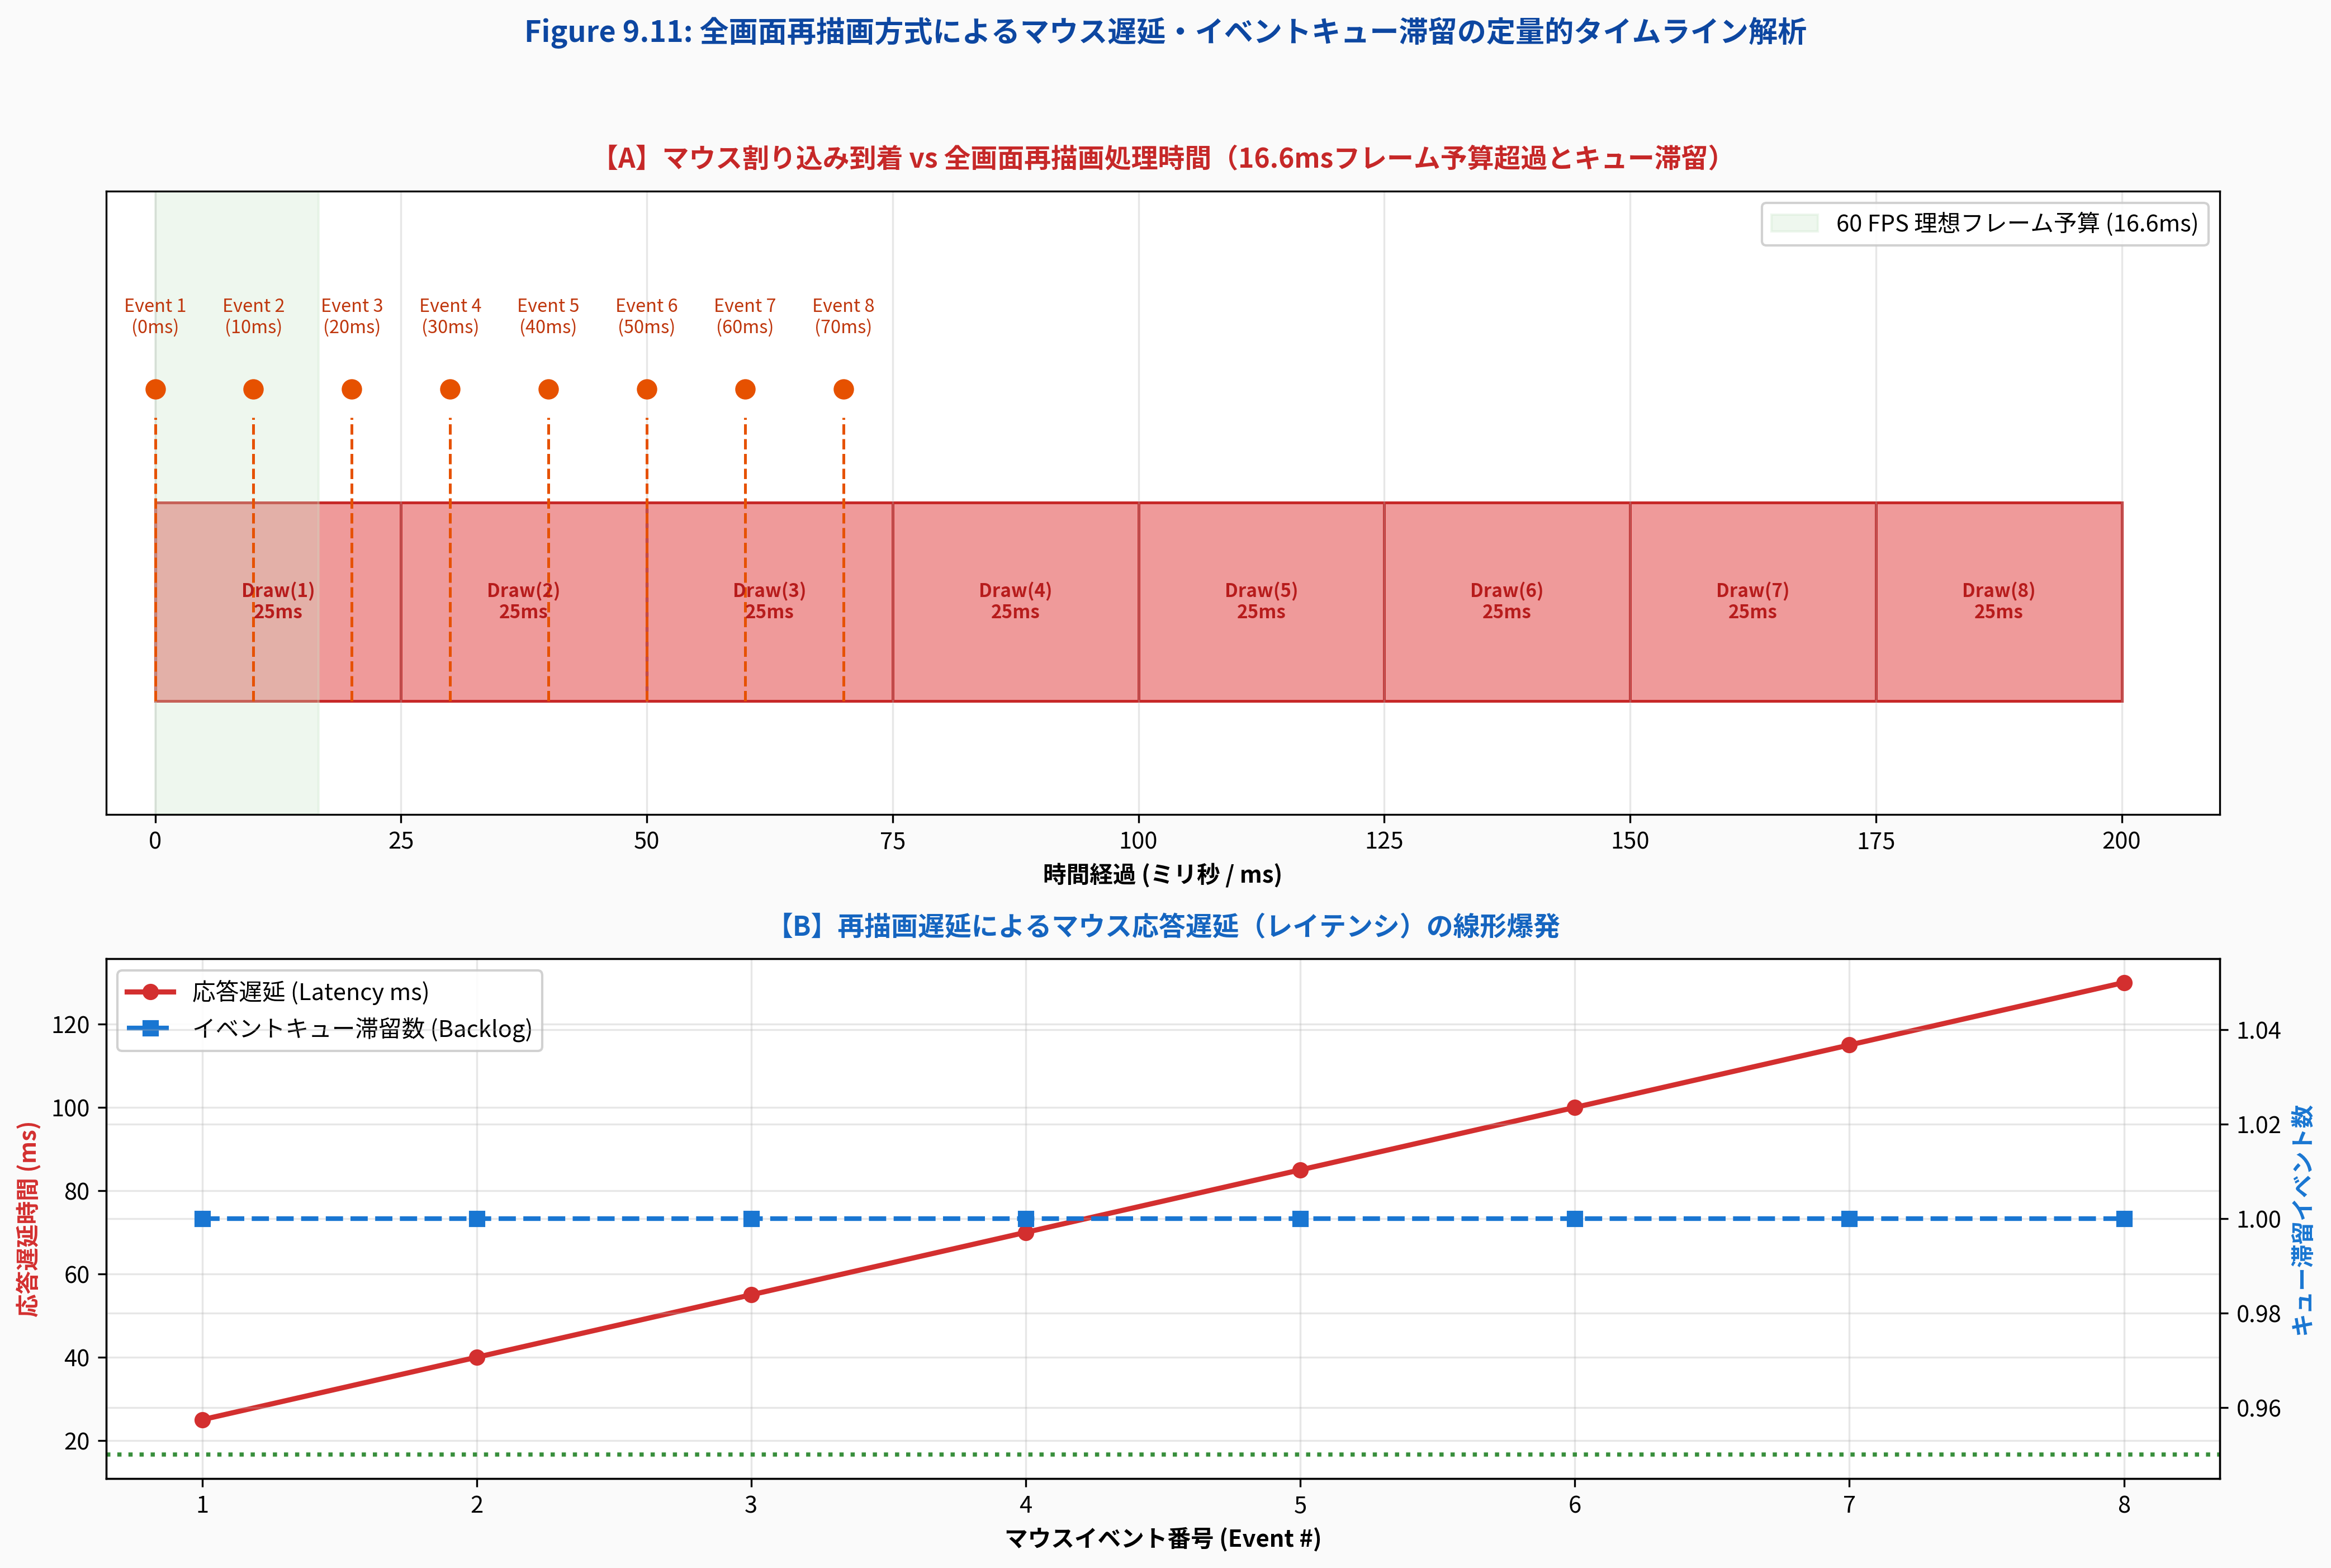

In [5]:
# Figure 9.11: マウスイベント到着 vs 全画面再描画タイムラインとキュー滞留図版生成
from common import plot_fig9_11_full_redraw_overhead_and_mouse_latency_timeline
from IPython.display import Image, display

fig_path = plot_fig9_11_full_redraw_overhead_and_mouse_latency_timeline()
display(Image(filename=str(fig_path)))


---

## 4. 全画面再描画 $O(W \cdot H)$ vs 差分再描画 $O(w \cdot h)$ の計算量分析

この性能問題を解決するための鍵は、**「マウスが動いたとき、本当に画面全体を描き直す必要があるのか？」** という根本的な問いにあります。

### 4.1 ピクセル走査量の圧倒的格差
- **画面全体のピクセル数**: $1024 \times 768 = 786,432$ ピクセル（約 78.6 万 px）
- **マウスカーソルのピクセル数**: $16 \times 24 = 384$ ピクセル
- **マウスが動いたときの影響領域（旧位置＋新位置の矩形領域）**: 約 $768$ ピクセル

$$\text{Speedup Ratio} = \frac{786,432}{768} \approx 1,024 \text{ 倍}$$

なんと、全画面再描画では**描画処理の 99.9% 以上が完全に無駄な上書き**だったのです！
次節（9.5節）では、移動前後の矩形領域（Bounding Box）だけを再描画する「部分再描画（Dirty Rectangle Redraw）」を導入し、この 1000 倍の無駄を徹底的に排除します。


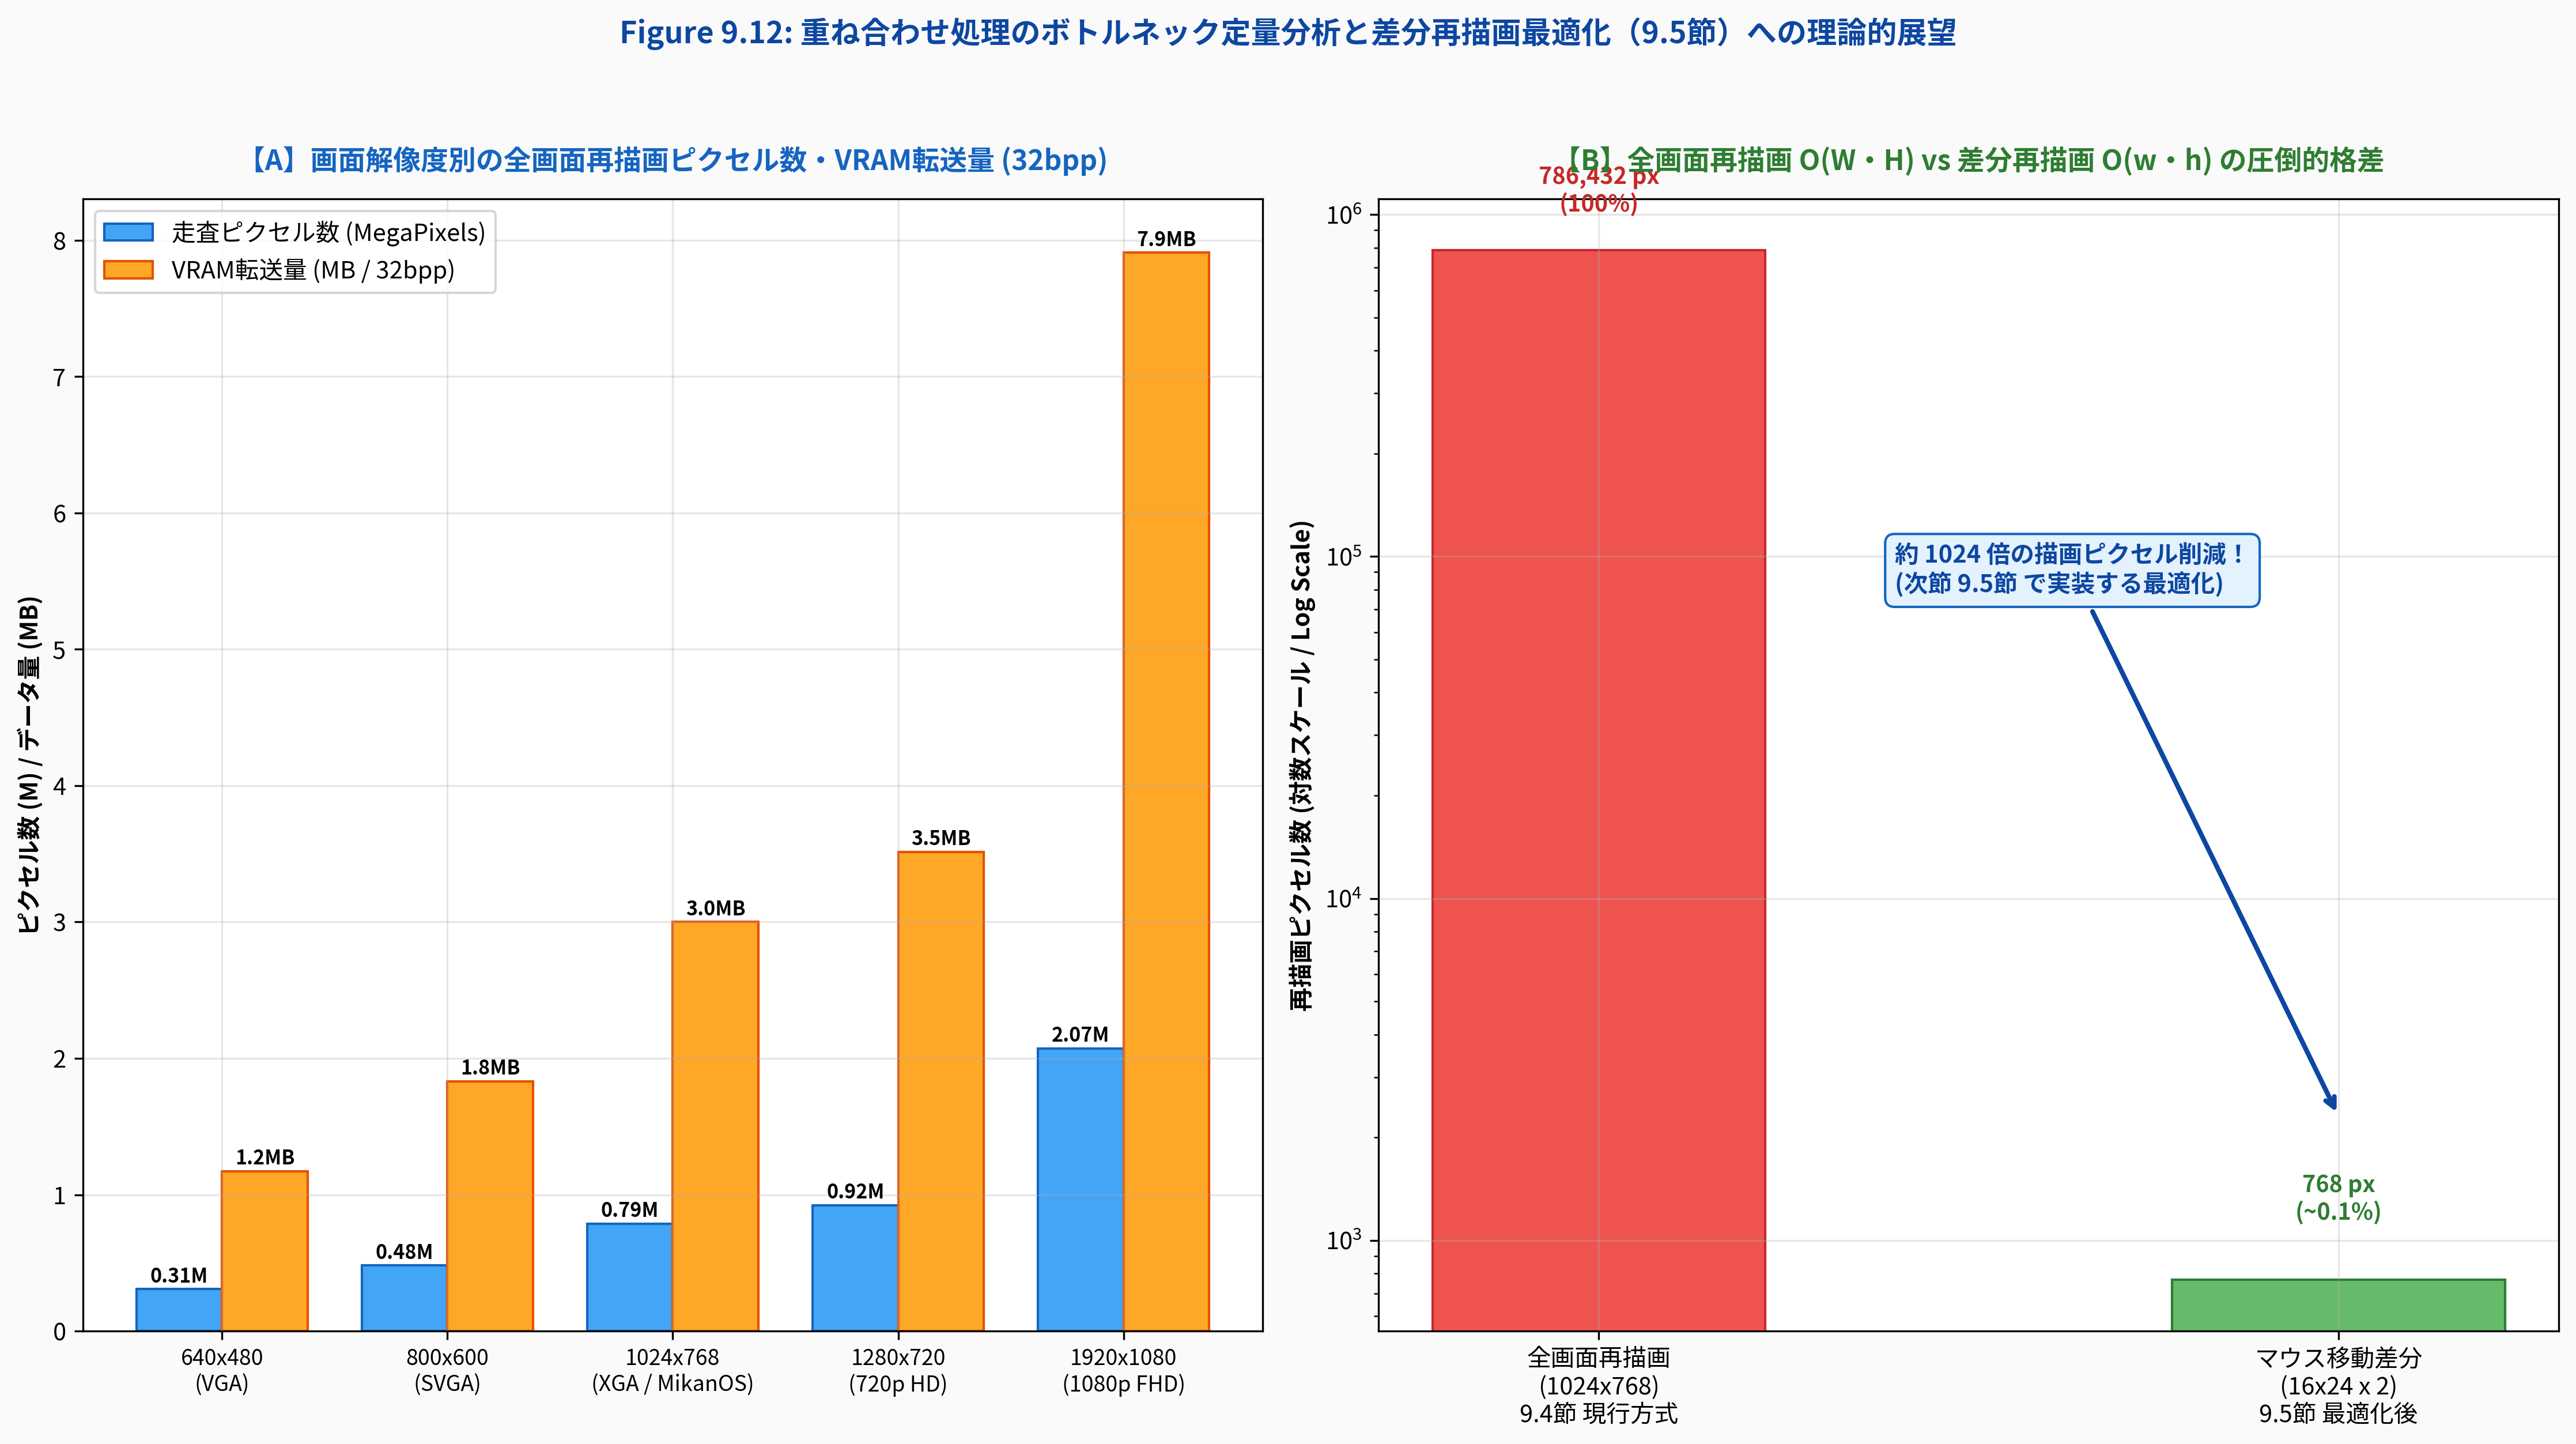

In [6]:
# Figure 9.12: 全画面再描画 vs 差分再描画の計算量・メモリアクセス量比較図版生成
from common import plot_fig9_12_compositing_performance_profiling_and_complexity_analysis
from IPython.display import Image, display

fig_path = plot_fig9_12_compositing_performance_profiling_and_complexity_analysis()
display(Image(filename=str(fig_path)))


---

## 5. ホスト側 C++20 単体検証プログラムによる実証

`src/ch09/os_chapter9_profiling_compositing.cpp` では、MikanOS の Local APIC タイマ MMIO レジスタ、`Window`, `Layer`, `LayerManager`、`MouseObserver` の動作をホスト環境（Linux / C++20）上で完全に再現し、自動テストを行います。


In [7]:
# C++20 単体検証プログラムのコンパイルと実行
!g++ -std=c++20 -O2 -Wall -Wextra src/ch09/os_chapter9_profiling_compositing.cpp -o build/bin/ch09_profiling_compositing
!./build/bin/ch09_profiling_compositing


  MikanOS Chapter 9.4: Compositing Performance Profiling & LAPIC   
[Test 1] Testing Local APIC Timer MMIO register decoding and countdown...
  ✓ Local APIC Timer MMIO registers and countdown verified.
[Test 2] Testing Layer Compositing Full Redraw and Profiling...
  LayerManager::Draw() written pixels: 38054, simulated LAPIC ticks: 380540
  ✓ LayerManager::Draw() full compositing profiling verified.
[Test 3] Simulating MouseObserver relative movements and redraw latency...
  ✓ MouseObserver simulation with LAPIC timer verified.
[Test 4] Analyzing O(W * H) Full Redraw vs O(w * h) Dirty-Rect Redraw...
  Full Screen Redraw Pixels : 786432 px
  Dirty Rect Redraw Pixels  : 768 px
  Theoretical Speedup Ratio : 1024.0x
  ✓ Complexity disparity verified (>1000x speedup potential).

[PASS] All Chapter 9.4 C++20 profiling and LAPIC timer tests passed!


---

## 6. まとめと次節（9.5節）への展望

### 本節で学んだ最重要概念
1. **推測するな、計測せよ (Measure, Don't Guess)**:
   - システムの性能問題に直面した際、感覚で最適化するのではなく、客観的なタイマ計測によってボトルネックを突き止める重要性を理解しました。
2. **Local APIC (LAPIC) タイマの MMIO 制御**:
   - 物理アドレス `0xFEE00000` に配置されたレジスタ群（`divide_config`, `lvt_timer`, `initial_count`, `current_count`）のビット構成を学び、割り込みをマスクした高精度ワンショットタイマとしての使い方を体得しました。
3. **全画面再描画の破綻と 1000 倍の無駄**:
   - $1024 \times 768$ 画面においてマウスが動くたびに全ピクセル（約78.6万px）を再描画することは、フレーム予算（16.6ms）を大幅に超過し、マウス遅延を引き起こす元凶であることを突き止めました。

### 次節 9.5節「重ね合わせ処理の高速化 (`osbook_day09c`)」へ！
原因が完全に特定されたため、次節では移動前後の矩形領域（`Rectangle`）の重なり判定を行い、**変化のあった必要最小限の領域のみを再描画する「部分再描画最適化」**を実装します！
